In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Flatten, Dropout
from keras.models import Sequential
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\Nikss\Self Pracitce\Deep learning\23 Day 23 - Social_Network_Ads.csv')

In [3]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [5]:
x = df.iloc[:, 0:2]
y = df.drop(x, axis = 'columns')

In [7]:
x.head()

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [8]:
y.head()

,Purchased
0,0
1,0
2,0
3,0
4,0


<AxesSubplot: xlabel='Age', ylabel='EstimatedSalary'>

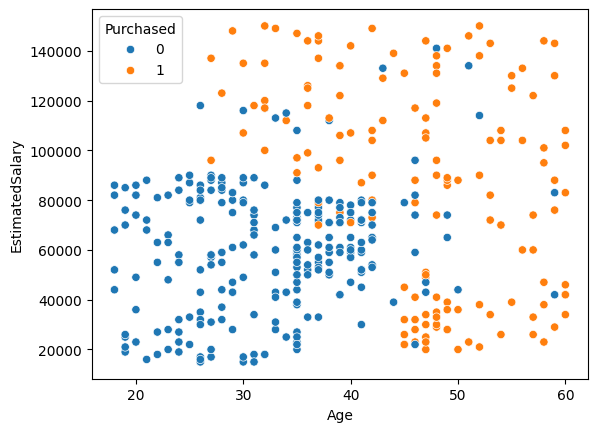

In [9]:
sns.scatterplot(data = df, x = 'Age', y = 'EstimatedSalary', hue = 'Purchased')

In [10]:
# TRain-Test split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [11]:
x_train.head()

,Age,EstimatedSalary
93,29,28000
23,45,22000
299,46,117000
13,32,18000
90,22,81000


In [12]:
# Scaling

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

x_train = ss.fit_transform(x_train)
x_test = ss.transform(x_test)

In [13]:
x_train[0:5]

array([[-0.80330081, -1.19121795],
       [ 0.75697997, -1.36859801],
       [ 0.85449752,  1.43991958],
       [-0.51074816, -1.48685138],
       [-1.48592365,  0.37563923]])

In [15]:
y_train[0:5]

,Purchased
93,0
23,1
299,1
13,0
90,0


# Model without Dropout layer.

In [16]:
model = Sequential()

model.add(Dense(128, activation = 'relu', input_dim = 2))
model.add(Dense(128, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

In [17]:
from keras.optimizers import Adam

adam = Adam(learning_rate = 0.01)

model.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [18]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               384       
                                                                 
 dense_1 (Dense)             (None, 128)               16512     
                                                                 
 dense_2 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17025 (66.50 KB)
Trainable params: 17025 (66.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [19]:
history = model.fit(x_train, y_train, epochs = 500, validation_data = (x_test, y_test))

Epoch 1/500
10/10 [==============================] - 1s 38ms/step - loss: 0.4009 - accuracy: 0.8188 - val_loss: 0.3798 - val_accuracy: 0.8750
Epoch 2/500
10/10 [==============================] - 0s 7ms/step - loss: 0.2360 - accuracy: 0.9250 - val_loss: 0.3142 - val_accuracy: 0.8625
Epoch 3/500
10/10 [==============================] - 0s 7ms/step - loss: 0.2259 - accuracy: 0.9250 - val_loss: 0.3661 - val_accuracy: 0.8625
Epoch 4/500
10/10 [==============================] - 0s 7ms/step - loss: 0.2087 - accuracy: 0.9312 - val_loss: 0.3199 - val_accuracy: 0.8625
Epoch 5/500
10/10 [==============================] - 0s 9ms/step - loss: 0.2014 - accuracy: 0.9344 - val_loss: 0.3894 - val_accuracy: 0.8625
Epoch 6/500
10/10 [==============================] - 0s 9ms/step - loss: 0.2096 - accuracy: 0.9250 - val_loss: 0.3568 - val_accuracy: 0.8625
Epoch 7/500
10/10 [==============================] - 0s 6ms/step - loss: 0.2018 - accuracy: 0.9344 - val_loss: 0.3391 - val_accuracy: 0.8625
Epoch 8/500


9600/9600 [==============================] - 12s 1ms/step


Text(0.5, 1.0, 'Without dropout layer')

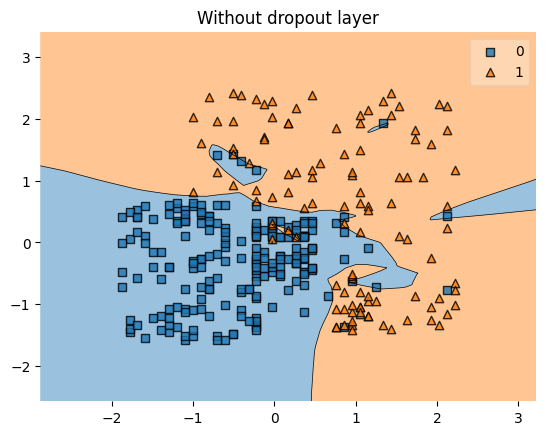

In [20]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(x_train, y_train.values.ravel(), clf = model)
plt.title("Without dropout layer")

`Looking to the decision boundries, we can easily see that the model is trying to byheart the data. 
Infact, it is making the other decision boundries as well, to capture the blue points in the region of orange points. This cleary shows the tendency of overfitting.`



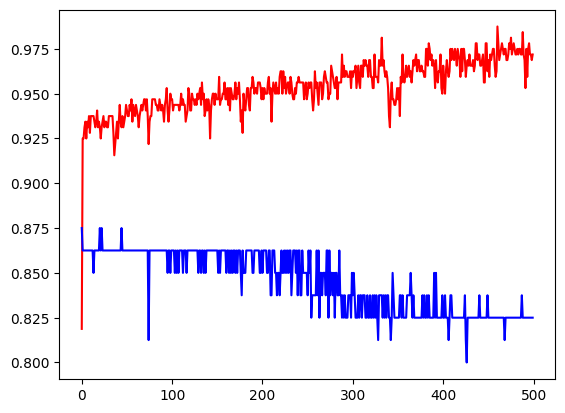

In [21]:
plt.plot(history.history['accuracy'], color = 'red', label = 'Training_Acc')
plt.plot(history.history['val_accuracy'], color = 'blue')

`We can see a high gap between training and validation accuracy, which again indicates overfitting`

# Using Dropout layer

In [22]:
model2 = Sequential()

model2.add(Dense(128, activation = 'relu', input_dim = 2))
model2.add(Dropout(0.2))
model2.add(Dense(128, activation = 'relu'))
model2.add(Dropout(0.2))
model2.add(Dense(1, activation = 'sigmoid'))

In [23]:
adam = Adam(learning_rate = 0.01)

model2.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [24]:
history2 = model2.fit(x_train, y_train, epochs = 500, validation_data = (x_test, y_test))

Epoch 1/500
10/10 [==============================] - 1s 28ms/step - loss: 0.4216 - accuracy: 0.8313 - val_loss: 0.3885 - val_accuracy: 0.8875
Epoch 2/500
10/10 [==============================] - 0s 6ms/step - loss: 0.2390 - accuracy: 0.9125 - val_loss: 0.3683 - val_accuracy: 0.8625
Epoch 3/500
10/10 [==============================] - 0s 6ms/step - loss: 0.2275 - accuracy: 0.9344 - val_loss: 0.3741 - val_accuracy: 0.8750
Epoch 4/500
10/10 [==============================] - 0s 6ms/step - loss: 0.2210 - accuracy: 0.9344 - val_loss: 0.3429 - val_accuracy: 0.8625
Epoch 5/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2069 - accuracy: 0.9344 - val_loss: 0.3525 - val_accuracy: 0.8625
Epoch 6/500
10/10 [==============================] - 0s 7ms/step - loss: 0.1936 - accuracy: 0.9312 - val_loss: 0.3483 - val_accuracy: 0.8625
Epoch 7/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2144 - accuracy: 0.9344 - val_loss: 0.3498 - val_accuracy: 0.8625
Epoch 8/500


9600/9600 [==============================] - 14s 1ms/step


Text(0.5, 1.0, 'P = 0.2')

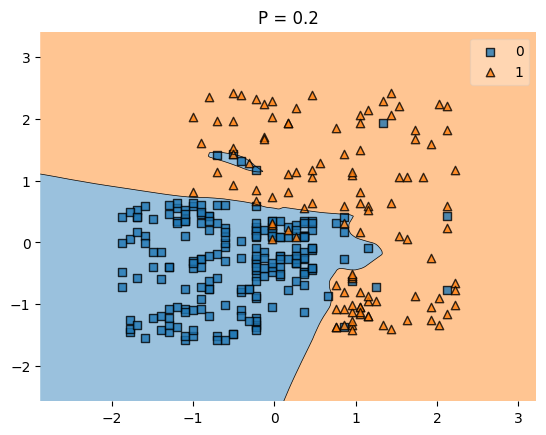

In [25]:
plot_decision_regions(x_train, y_train.values.ravel(), clf = model2)
plt.title('P = 0.2')

` We can see it is still making various decisios boundries and trying to capture every points of the dataset, which clearly 
indicates overfitting.`

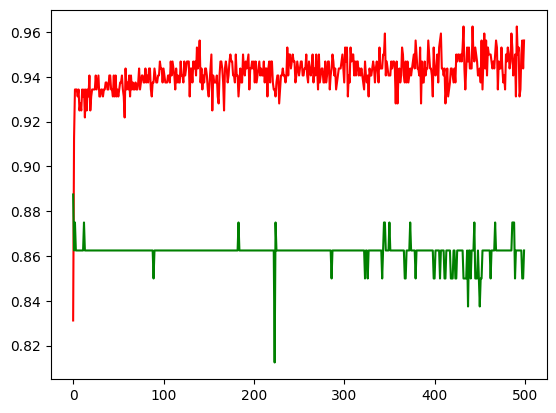

In [27]:
plt.plot(history2.history['accuracy'], color = 'red')
plt.plot(history2.history['val_accuracy'], color = 'green')

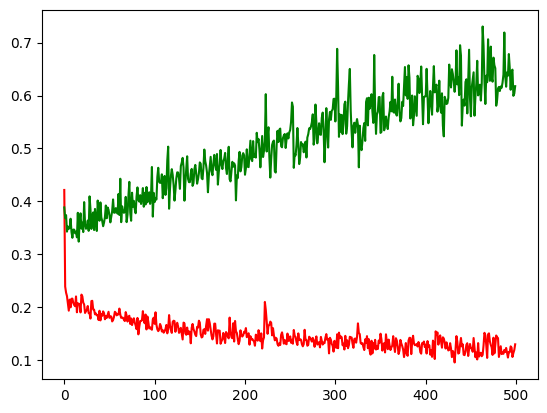

In [28]:
plt.plot(history2.history['loss'], color = 'red')
plt.plot(history2.history['val_loss'], color = 'green')

`We can observe a great decrement in overfitting before and after Dropout layer.`

# Now let's use dropout = 0.5 and see the change.

In [29]:
model3 = Sequential()
model3.add(Dense(128, activation = 'relu', input_dim = 2))
model3.add(Dropout(0.5))
model3.add(Dense(128, activation = 'relu'))
model3.add(Dropout(0.5))
model3.add(Dense(1, activation = 'sigmoid'))

In [30]:
adam = Adam(learning_rate = 0.01)

model3.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [31]:
history3 = model3.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 500)

Epoch 1/500
10/10 [==============================] - 1s 29ms/step - loss: 0.4475 - accuracy: 0.8031 - val_loss: 0.4090 - val_accuracy: 0.8375
Epoch 2/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2762 - accuracy: 0.9062 - val_loss: 0.3660 - val_accuracy: 0.8875
Epoch 3/500
10/10 [==============================] - 0s 7ms/step - loss: 0.2721 - accuracy: 0.9187 - val_loss: 0.3477 - val_accuracy: 0.8625
Epoch 4/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2175 - accuracy: 0.9125 - val_loss: 0.3643 - val_accuracy: 0.8625
Epoch 5/500
10/10 [==============================] - 0s 7ms/step - loss: 0.2332 - accuracy: 0.9250 - val_loss: 0.3669 - val_accuracy: 0.8625
Epoch 6/500
10/10 [==============================] - 0s 7ms/step - loss: 0.2335 - accuracy: 0.9125 - val_loss: 0.3406 - val_accuracy: 0.8625
Epoch 7/500
10/10 [==============================] - 0s 6ms/step - loss: 0.2197 - accuracy: 0.9187 - val_loss: 0.3219 - val_accuracy: 0.8625
Epoch 8/500


9600/9600 [==============================] - 14s 1ms/step


Text(0.5, 1.0, 'P = 0.5')

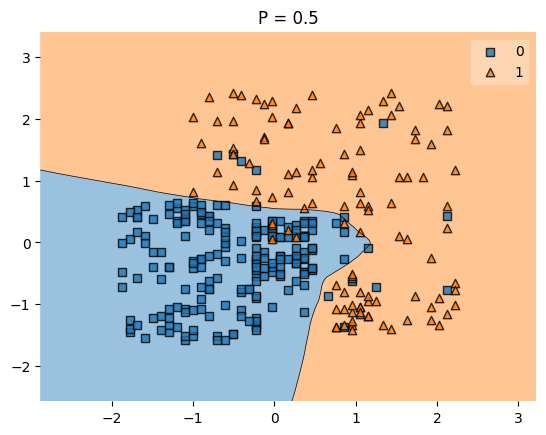

In [32]:
plot_decision_regions(x_train, y_train.values.ravel(), clf = model3)
plt.title('P = 0.5')

` We can see this is giving us the better decission boundry than p = 0.2 as it is not trying to 
capture the points on the other side and not trying to byheart the data as well.`

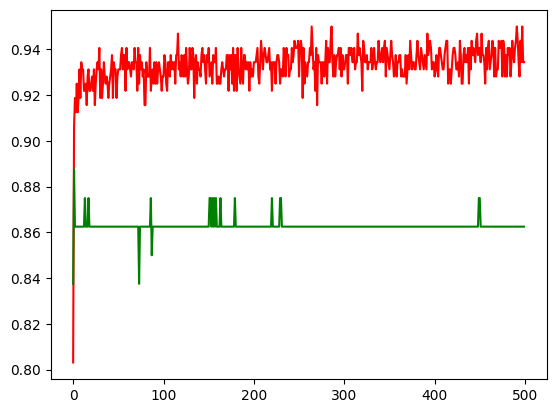

In [33]:
plt.plot(history3.history['accuracy'], color = 'red')
plt.plot(history3.history['val_accuracy'], color = 'green')

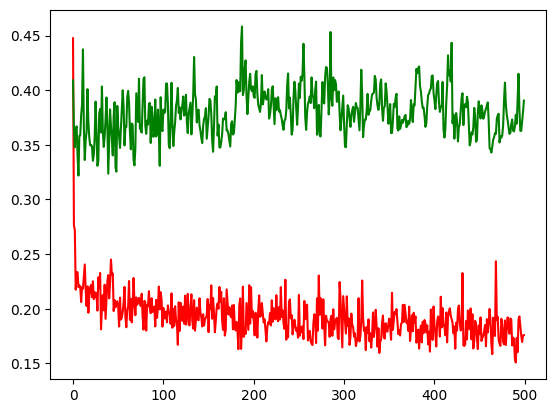

In [34]:
plt.plot(history3.history['loss'], color = 'red')
plt.plot(history3.history['val_loss'], color = 'green')

# Just trying with a more complex model.

In [35]:
model4 = Sequential()

model4.add(Dense(256, activation = 'relu', input_dim = 2))
model4.add(Dropout(0.5))
model4.add(Dense(128, activation = 'relu'))
model4.add(Dropout(0.5))
model4.add(Dense(128, activation = 'relu'))
model4.add(Dropout(0.5))
model4.add(Dense(64, activation = 'relu'))
model4.add(Dropout(0.5))
model4.add(Dense(1, activation = 'sigmoid'))

In [36]:
adam = Adam(learning_rate = 0.01)

model4.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [37]:
history4 = model4.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 500)

Epoch 1/500
10/10 [==============================] - 1s 29ms/step - loss: 0.5062 - accuracy: 0.7781 - val_loss: 0.4572 - val_accuracy: 0.8625
Epoch 2/500
10/10 [==============================] - 0s 8ms/step - loss: 0.3623 - accuracy: 0.8844 - val_loss: 0.4237 - val_accuracy: 0.8750
Epoch 3/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2563 - accuracy: 0.9219 - val_loss: 0.3575 - val_accuracy: 0.8625
Epoch 4/500
10/10 [==============================] - 0s 8ms/step - loss: 0.3063 - accuracy: 0.8906 - val_loss: 0.3504 - val_accuracy: 0.8625
Epoch 5/500
10/10 [==============================] - 0s 9ms/step - loss: 0.2975 - accuracy: 0.9187 - val_loss: 0.3020 - val_accuracy: 0.8625
Epoch 6/500
10/10 [==============================] - 0s 10ms/step - loss: 0.2594 - accuracy: 0.9250 - val_loss: 0.3587 - val_accuracy: 0.8625
Epoch 7/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2841 - accuracy: 0.9094 - val_loss: 0.3136 - val_accuracy: 0.8625
Epoch 8/500

9600/9600 [==============================] - 17s 2ms/step


Text(0.5, 1.0, 'P = 0.5')

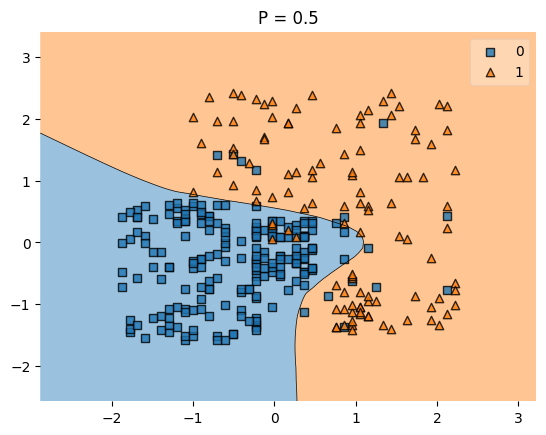

In [38]:
plot_decision_regions(x_train, y_train.values.ravel(), clf = model4)
plt.title('P = 0.5')

` This is giving almost same decision boundry as in above model where p = 0.5.`

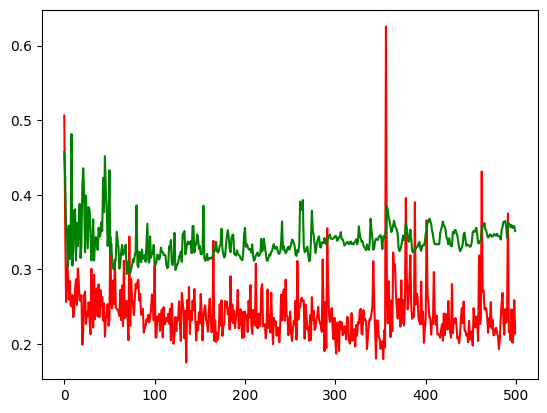

In [39]:
plt.plot(history4.history['loss'], color = 'red')
plt.plot(history4.history['val_loss'], color = 'green')

` But this is reducing training and validation loss to a great extent than the above model where p = 0.5
Hence we can say this model is better than that one.`

`Now let's plt training and val accuracy also`

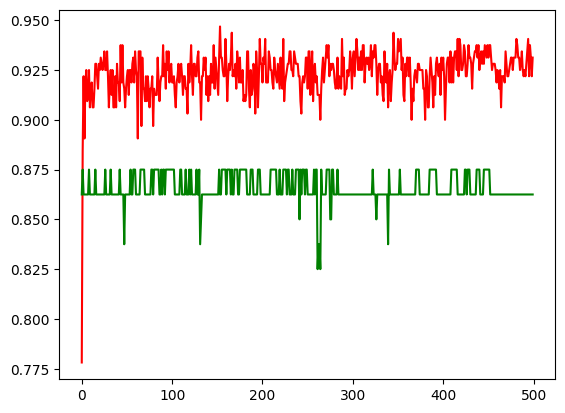

In [40]:
plt.plot(history4.history['accuracy'], color = 'red')
plt.plot(history4.history['val_accuracy'], color = 'green')

` It is increasing somewhat accuracy than the previous model where p = 0.5`

# Let's use earlystopping as well in this complex model ans see the result.

In [44]:
from keras.callbacks import EarlyStopping

In [61]:
callback = EarlyStopping(
    monitor="val_accuracy",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [68]:
model5 = Sequential()

model5.add(Dense(256, activation = 'relu', input_dim = 2))
model5.add(Dropout(0.3))
model5.add(Dense(128, activation = 'relu'))
model5.add(Dropout(0.3))
model5.add(Dense(128, activation = 'relu'))
model5.add(Dropout(0.3))
model5.add(Dense(64, activation = 'relu'))
model5.add(Dropout(0.3))
model5.add(Dense(1, activation = 'sigmoid'))

In [69]:
from keras.optimizers import Adam

adam = Adam(learning_rate = 0.01)
model5.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [70]:
history5 = model5.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 500, callbacks = callback)

Epoch 1/500
10/10 [==============================] - 1s 25ms/step - loss: 0.4204 - accuracy: 0.7750 - val_loss: 0.3934 - val_accuracy: 0.8625
Epoch 2/500
10/10 [==============================] - 0s 9ms/step - loss: 0.2744 - accuracy: 0.9094 - val_loss: 0.3726 - val_accuracy: 0.8625
Epoch 3/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2541 - accuracy: 0.9312 - val_loss: 0.3596 - val_accuracy: 0.8625
Epoch 4/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2331 - accuracy: 0.9125 - val_loss: 0.3784 - val_accuracy: 0.8750
Epoch 5/500
10/10 [==============================] - 0s 10ms/step - loss: 0.2375 - accuracy: 0.9187 - val_loss: 0.4040 - val_accuracy: 0.8625
Epoch 6/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2577 - accuracy: 0.9250 - val_loss: 0.3410 - val_accuracy: 0.8750
Epoch 7/500
10/10 [==============================] - 0s 8ms/step - loss: 0.2351 - accuracy: 0.9156 - val_loss: 0.3520 - val_accuracy: 0.8750
Epoch 8/500

9600/9600 [==============================] - 19s 2ms/step


Text(0.5, 1.0, 'P = 0.5 and EarlyStopping')

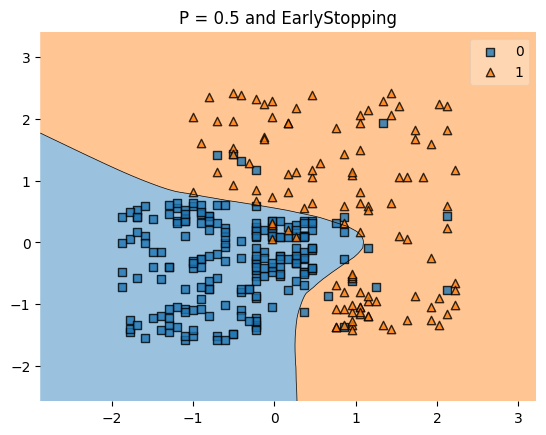

In [71]:
plot_decision_regions(x_train, y_train.values.ravel(), clf = model4)
plt.title('P = 0.5 and EarlyStopping')

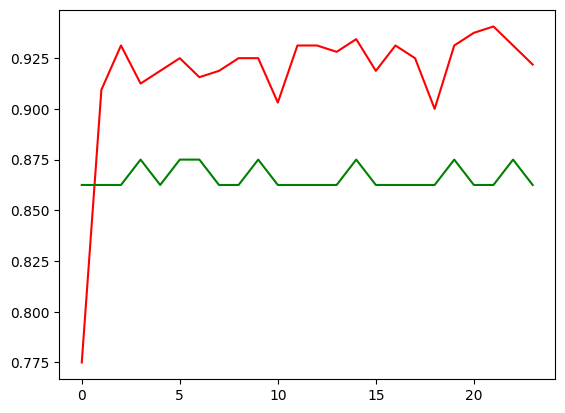

In [72]:
plt.plot(history5.history['accuracy'], color = 'red')
plt.plot(history5.history['val_accuracy'], color = 'green')

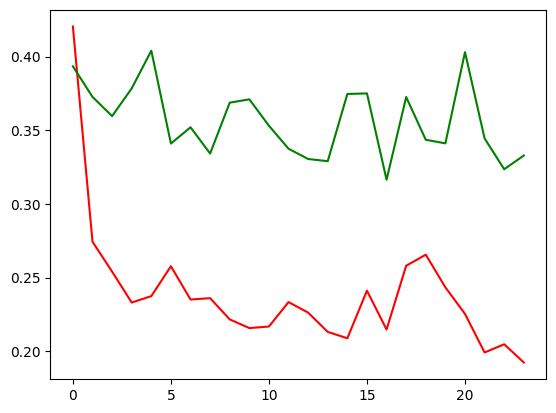

In [73]:
plt.plot(history5.history['loss'], color = 'red')
plt.plot(history5.history['val_loss'], color = 'green')

`In many cases, it is seen that dropout is applied to the output of the last hidden layer,
so try with that as well and see the result.`